# NB27 — Model Selection and Interpretation Pitfalls

> **StatQuest principle: a model that fits well is not the same as a model you can trust.**

---

## The main ideas are:

1. **Metrics:** MSE, RMSE, MAE, R² — and when to prefer MAE over RMSE
2. **AIC / BIC** trade fit against complexity — lower is better
3. **Nested models:** the partial **F-test** asks "do these extra variables help, together?"
4. **Stepwise selection** by AIC is convenient but makes the chosen model look **more significant than it is**
5. **Omitted-variable bias:** leave out a variable correlated with x and x's coefficient absorbs its effect: bias = β₂·δ
6. **Extrapolation:** a line that fits inside the data can be badly wrong outside it
7. **Correlation ≠ causation:** a confounder can create a "significant" slope out of nothing


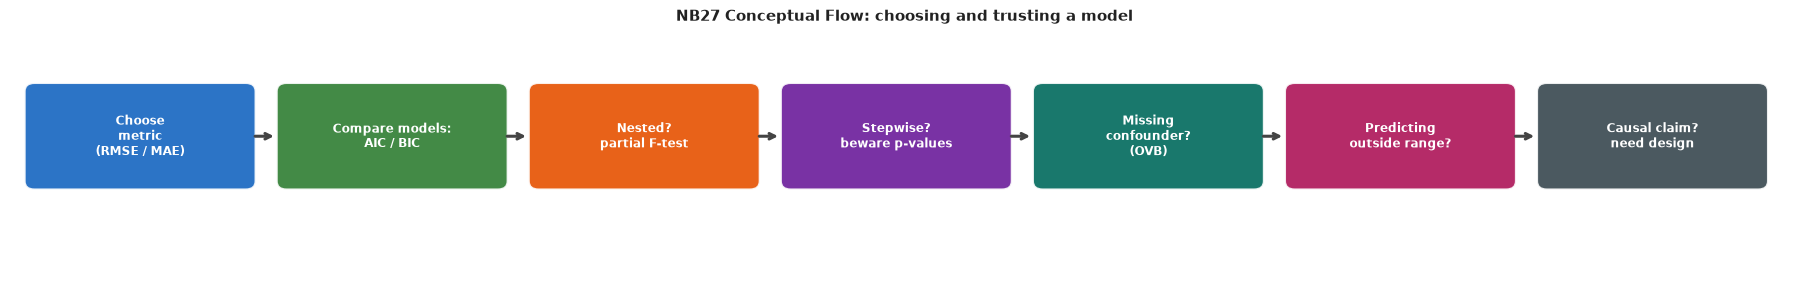

In [1]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyBboxPatch

def flow_diagram(steps, title, colors=None, notes=None, figsize=(14, 2.8)):
    """Draw a horizontal flow diagram.  steps = list of strings."""
    n = len(steps)
    default_colors = [
        '#1565C0','#2E7D32','#E65100','#6A1B9A',
        '#00695C','#AD1457','#37474F','#4E342E',
        '#0277BD','#558B2F',
    ]
    colors = (colors or default_colors[:n]) + default_colors
    notes  = notes or [''] * n

    fig, ax = plt.subplots(figsize=figsize)
    ax.set_xlim(-0.3, n * 3.1)
    ax.set_ylim(-1.2, 2.4)
    ax.axis('off')

    bw, bh = 2.6, 1.3
    for i, (step, color, note) in enumerate(zip(steps, colors, notes)):
        x = i * 3.1
        box = FancyBboxPatch((x, 0.2), bw, bh,
                             boxstyle="round,pad=0.12",
                             facecolor=color, edgecolor='white', linewidth=1.5, alpha=0.90)
        ax.add_patch(box)
        ax.text(x + bw/2, 0.2 + bh/2, step,
                ha='center', va='center', fontsize=8.5,
                color='white', fontweight='bold', multialignment='center')
        if note:
            ax.text(x + bw/2, 0.02, note,
                    ha='center', va='top', fontsize=7, color='#555', style='italic')
        if i < n - 1:
            ax.annotate('',
                xy=(x + bw + 0.38, 0.2 + bh/2),
                xytext=(x + bw + 0.08, 0.2 + bh/2),
                arrowprops=dict(arrowstyle='->', color='#444', lw=2.2))

    ax.set_title(title, fontsize=11, fontweight='bold', pad=6, color='#222')
    plt.tight_layout(pad=0.4)
    plt.show()

flow_diagram(
    steps=['Choose\nmetric\n(RMSE / MAE)', 'Compare models:\nAIC / BIC', 'Nested?\npartial F-test', 'Stepwise?\nbeware p-values',
           'Missing\nconfounder?\n(OVB)', 'Predicting\noutside range?', 'Causal claim?\nneed design'],
    title='NB27 Conceptual Flow: choosing and trusting a model',
    figsize=(18, 2.8),
)


## Step 1 — Metrics: MSE, RMSE, MAE, R²

```
MSE  = mean((y − ŷ)²)          RMSE = √MSE  (same units as y)
MAE  = mean(|y − ŷ|)           R²   = 1 − SS_res / SS_tot
```

- **RMSE** squares errors → large errors dominate. Use it when big misses are disproportionately costly.
- **MAE** treats every unit of error equally → robust to a few huge misses; it is the error of a "typical" prediction.
- Always report metrics on **held-out** data.


In [2]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import matplotlib.pyplot as plt

housing = fetch_california_housing()
X_tr, X_te, y_tr, y_te = train_test_split(housing.data, housing.target, test_size=0.2, random_state=0)
pred = LinearRegression().fit(X_tr, y_tr).predict(X_te)

mse = mean_squared_error(y_te, pred)
print("California Housing, test set (y in $100k):")
print(f"  MSE  = {mse:.4f}")
print(f"  RMSE = {np.sqrt(mse):.4f}   -> typical miss ~ ${np.sqrt(mse)*100:.0f}k (squared-error view)")
print(f"  MAE  = {mean_absolute_error(y_te, pred):.4f}   -> typical miss ~ ${mean_absolute_error(y_te, pred)*100:.0f}k")
print(f"  R^2  = {r2_score(y_te, pred):.4f}")

# How a few big misses move RMSE vs MAE
err  = np.full(100, 1.0)
err2 = err.copy(); err2[:5] = 10.0
print("\n100 errors of size 1  -> RMSE = %.2f, MAE = %.2f" % (np.sqrt(np.mean(err**2)), np.mean(np.abs(err))))
print("...5 of them become 10 -> RMSE = %.2f, MAE = %.2f" % (np.sqrt(np.mean(err2**2)), np.mean(np.abs(err2))))


California Housing, test set (y in $100k):
  MSE  = 0.5290
  RMSE = 0.7273   -> typical miss ~ $73k (squared-error view)
  MAE  = 0.5351   -> typical miss ~ $54k
  R^2  = 0.5943

100 errors of size 1  -> RMSE = 1.00, MAE = 1.00
...5 of them become 10 -> RMSE = 2.44, MAE = 1.45


## Step 2 — AIC and BIC

```
AIC = 2k − 2 ln L            BIC = k · ln(n) − 2 ln L
```

k = number of estimated parameters, L = maximised likelihood. Both reward fit (−2 ln L) and penalise complexity;
**BIC penalises more** (ln n > 2 once n ≥ 8) and prefers smaller models. Lower is better; only differences matter, and only between models fitted to the **same y**.

Data: y = 1 + 2·x1 + 1.5·x2 + 0.5·x3 + ε, with x4, x5 pure noise (n = 150, ε ~ N(0, 2²)).


In [3]:
rng = np.random.default_rng(21)
n   = 150
df  = pd.DataFrame(rng.normal(size=(n, 5)), columns=['x1', 'x2', 'x3', 'x4', 'x5'])
df['y'] = 1 + 2*df.x1 + 1.5*df.x2 + 0.5*df.x3 + rng.normal(0, 2, n)

formulas = ['y ~ x1', 'y ~ x1 + x2', 'y ~ x1 + x2 + x3', 'y ~ x1 + x2 + x3 + x4 + x5']
fits = {f: smf.ols(f, df).fit() for f in formulas}
print(f"{'model':28s}{'k':>3s}{'R^2':>8s}{'adj R^2':>9s}{'AIC':>9s}{'BIC':>9s}")
for f, r in fits.items():
    k = int(r.df_model) + 1
    print(f"{f:28s}{k:3d}{r.rsquared:8.4f}{r.rsquared_adj:9.4f}{r.aic:9.2f}{r.bic:9.2f}")

r = fits['y ~ x1 + x2 + x3']
k = int(r.df_model) + 1
print(f"\nManual check for y ~ x1 + x2 + x3: AIC = 2*{k} - 2*({r.llf:.3f}) = {2*k - 2*r.llf:.2f};  "
      f"BIC = {k}*ln({n}) - 2*({r.llf:.3f}) = {k*np.log(n) - 2*r.llf:.2f}")
print("Note: statsmodels' k counts the regression coefficients (incl. intercept), not sigma^2;")
print("      that constant offset cancels when comparing models.")


model                         k     R^2  adj R^2      AIC      BIC
y ~ x1                        2  0.3347   0.3302   711.21   717.24
y ~ x1 + x2                   3  0.6000   0.5946   636.88   645.91
y ~ x1 + x2 + x3              4  0.6144   0.6065   633.39   645.43
y ~ x1 + x2 + x3 + x4 + x5    6  0.6289   0.6160   631.64   649.70

Manual check for y ~ x1 + x2 + x3: AIC = 2*4 - 2*(-312.693) = 633.39;  BIC = 4*ln(150) - 2*(-312.693) = 645.43
Note: statsmodels' k counts the regression coefficients (incl. intercept), not sigma^2;
      that constant offset cancels when comparing models.


## Step 3 — Nested models: the partial F-test

Do x4 and x5 add anything **together**, once x1–x3 are in?

```
F = [(SSR_reduced − SSR_full) / q] / [SSR_full / (n − k_full)]       q = number of added variables
```

H0: the added coefficients are all zero.


In [4]:
from statsmodels.stats.anova import anova_lm
reduced = fits['y ~ x1 + x2 + x3']
full    = fits['y ~ x1 + x2 + x3 + x4 + x5']
print(anova_lm(reduced, full).round(4))
F, p, q = full.compare_f_test(reduced)
print(f"\nF = {F:.4f}, p = {p:.4f}, extra parameters q = {int(q)}")
print("-> p > 0.05: x4 and x5 do not improve the model. Keep the smaller one.")

reduced2 = fits['y ~ x1 + x2']
F2, p2, q2 = reduced.compare_f_test(reduced2)
print(f"\nAdding x3 to (x1, x2):  F = {F2:.4f}, p = {p2:.4f}")


   df_resid       ssr  df_diff  ss_diff       F  Pr(>F)
0     146.0  567.9334      0.0      NaN     NaN     NaN
1     144.0  546.5852      2.0  21.3483  2.8121  0.0634

F = 2.8121, p = 0.0634, extra parameters q = 2
-> p > 0.05: x4 and x5 do not improve the model. Keep the smaller one.

Adding x3 to (x1, x2):  F = 5.4487, p = 0.0209


## Step 4 — Forward stepwise selection by AIC (and why its p-values lie)

Algorithm: start empty; at each step add the variable that lowers AIC the most; stop when nothing lowers it.

**Caveat:** the selected model's p-values ignore that we *searched*. On pure noise, stepwise still "finds" significant predictors.


In [5]:
def forward_aic(data, target, candidates):
    chosen, best_aic = [], smf.ols(f'{target} ~ 1', data).fit().aic
    path = [('(intercept only)', best_aic)]
    while True:
        trials = [(smf.ols(f"{target} ~ {' + '.join(chosen + [c])}", data).fit().aic, c)
                  for c in candidates if c not in chosen]
        if not trials:
            break
        aic, c = min(trials)
        if aic >= best_aic:
            break
        chosen.append(c); best_aic = aic; path.append(('+ ' + c, aic))
    return chosen, path

chosen, path = forward_aic(df, 'y', ['x1', 'x2', 'x3', 'x4', 'x5'])
for step, aic in path:
    print(f"  {step:18s} AIC = {aic:.2f}")
print(f"Selected: {chosen}")
print("Note: x4 is pure noise, yet AIC kept it (AIC only needs a tiny likelihood gain). BIC or a hold-out set would be stricter.")


  (intercept only)   AIC = 770.33
  + x1               AIC = 711.21
  + x2               AIC = 636.88
  + x3               AIC = 633.39
  + x4               AIC = 631.54
Selected: ['x1', 'x2', 'x3', 'x4']
Note: x4 is pure noise, yet AIC kept it (AIC only needs a tiny likelihood gain). BIC or a hold-out set would be stricter.


In [6]:
# Pure noise: 20 candidate predictors, none related to y
rng0  = np.random.default_rng(4)
noise = pd.DataFrame(rng0.normal(size=(100, 20)), columns=[f'z{i}' for i in range(1, 21)])
noise['y'] = rng0.normal(size=100)
sel, _ = forward_aic(noise, 'y', [f'z{i}' for i in range(1, 21)])
res    = smf.ols('y ~ ' + ' + '.join(sel), noise).fit() if sel else None
print(f"Variables selected from pure noise: {sel}")
if res is not None:
    print(res.pvalues.drop('Intercept').round(4).to_string())
    print(f"-> {int((res.pvalues.drop('Intercept') < 0.05).sum())} of {len(sel)} look 'significant' at 5% — yet y is pure noise.")
print("Fix: validate on held-out data, use cross-validation (NB14) or Lasso (NB12) instead of trusting post-selection p-values.")


Variables selected from pure noise: ['z9', 'z3', 'z20', 'z12', 'z16', 'z17']
z9     0.0459
z3     0.0178
z20    0.0737
z12    0.1376
z16    0.1130
z17    0.1402
-> 2 of 6 look 'significant' at 5% — yet y is pure noise.
Fix: validate on held-out data, use cross-validation (NB14) or Lasso (NB12) instead of trusting post-selection p-values.


## Step 5 — Omitted-variable bias (OVB)

True model: y = β0 + β1·x1 + β2·x2 + ε. If you **omit x2**, the slope on x1 becomes

```
b1(short) = β1 + β2 · δ        δ = slope from regressing x2 on x1
```

The bias β2·δ is non-zero when x2 **affects y** (β2 ≠ 0) **and** is **correlated with x1** (δ ≠ 0).
This identity holds **exactly** for the fitted OLS coefficients in any sample.

Example: wage depends on education and (unobserved) ability; abler people also get more education.


In [7]:
rng = np.random.default_rng(8)
n   = 1000
ability = rng.normal(0, 1, n)
edu     = 12 + 2 * ability + rng.normal(0, 1, n)
wage    = 5 + 1.0 * edu + 3.0 * ability + rng.normal(0, 2, n)

long_  = sm.OLS(wage, sm.add_constant(np.column_stack([edu, ability]))).fit()
short  = sm.OLS(wage, sm.add_constant(edu)).fit()
delta  = sm.OLS(ability, sm.add_constant(edu)).fit().params[1]

print(f"True effect of 1 year of education      : 1.000")
print(f"Long regression (with ability)          : {long_.params[1]:.4f}")
print(f"Short regression (ability omitted)      : {short.params[1]:.4f}")
print(f"OVB formula  b_long + b_ability * delta : {long_.params[1]:.4f} + {long_.params[2]:.4f} * {delta:.4f} = {long_.params[1] + long_.params[2]*delta:.4f}")
print(f"Theory: delta = Cov(ability, edu)/Var(edu) = 2/5 = 0.4 -> bias = 3 * 0.4 = 1.2")


True effect of 1 year of education      : 1.000
Long regression (with ability)          : 1.1255
Short regression (ability omitted)      : 2.2885
OVB formula  b_long + b_ability * delta : 1.1255 + 2.8749 * 0.4045 = 2.2885
Theory: delta = Cov(ability, edu)/Var(edu) = 2/5 = 0.4 -> bias = 3 * 0.4 = 1.2


### The same mechanism: a missing interaction term (NB10)

In NB10 the true salary model had an interaction:  salary = 30 + 2·exper + 10·edu + 3.5·exper·edu.
Leaving out **exper·edu** is an omitted variable too — and the degree dummy absorbs it.


In [8]:
np.random.seed(7)
n = 200
edu_d  = np.random.binomial(1, 0.5, n).astype(float)
exper  = np.random.uniform(1, 20, n)
salary = 30 + 2.0*exper + 10*edu_d + 3.5*exper*edu_d + np.random.normal(0, 4, n)

X_short = sm.add_constant(np.column_stack([exper, edu_d]))
X_long  = sm.add_constant(np.column_stack([exper, edu_d, exper*edu_d]))
s, l    = sm.OLS(salary, X_short).fit(), sm.OLS(salary, X_long).fit()
d       = sm.OLS(exper*edu_d, X_short).fit().params      # regress omitted term on included ones

print(f"edu coefficient WITHOUT interaction : {s.params[2]:.4f}   (true edu effect at exper = 0: 10)")
print(f"edu coefficient WITH interaction    : {l.params[2]:.4f}")
print(f"OVB identity: {l.params[2]:.4f} + {l.params[3]:.4f} * {d[2]:.4f} = {l.params[2] + l.params[3]*d[2]:.4f}")
print(f"(delta = {d[2]:.2f} is roughly the average experience of degree holders: {exper[edu_d==1].mean():.2f})")


edu coefficient WITHOUT interaction : 47.3001   (true edu effect at exper = 0: 10)
edu coefficient WITH interaction    : 10.0028
OVB identity: 10.0028 + 3.5028 * 10.6478 = 47.3001
(delta = 10.65 is roughly the average experience of degree holders: 10.57)


## Step 6 — Extrapolation: right inside the data, wrong outside it

True relationship saturates:  y = 10·(1 − e^(−0.5x)). We only observe x in [0, 5].


Linear fit on x in [0, 5]: R^2 = 0.8978
  x =  2.5: linear predicts   6.43, truth   7.13  (error  -0.70)
  x =  5.0: linear predicts  10.61, truth   9.18  (error  +1.43)
  x = 10.0: linear predicts  18.96, truth   9.93  (error  +9.03)
  x = 15.0: linear predicts  27.31, truth   9.99  (error +17.31)


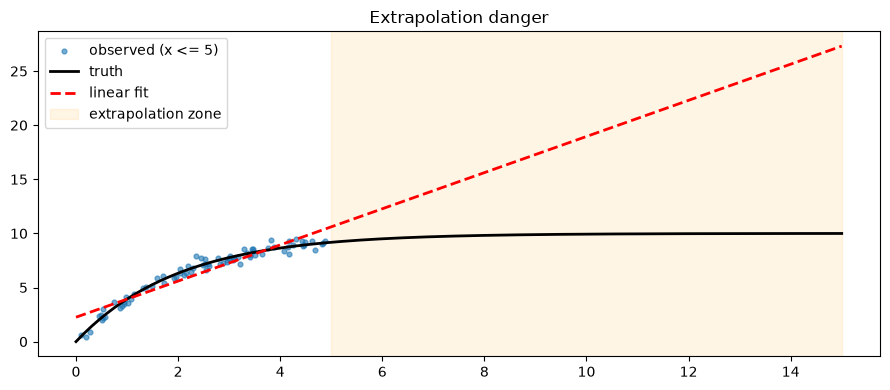

In [9]:
rng = np.random.default_rng(2)
x_tr = rng.uniform(0, 5, 80)
f    = lambda x: 10 * (1 - np.exp(-0.5 * x))
y_tr = f(x_tr) + rng.normal(0, 0.4, 80)
lin  = sm.OLS(y_tr, sm.add_constant(x_tr)).fit()

print(f"Linear fit on x in [0, 5]: R^2 = {lin.rsquared:.4f}")
for x0 in [2.5, 5, 10, 15]:
    p0 = lin.params[0] + lin.params[1] * x0
    print(f"  x = {x0:4.1f}: linear predicts {p0:6.2f}, truth {f(x0):6.2f}  (error {p0 - f(x0):+6.2f})")

xx = np.linspace(0, 15, 200)
fig, ax = plt.subplots(figsize=(9, 4))
ax.scatter(x_tr, y_tr, s=12, alpha=0.6, label='observed (x <= 5)')
ax.plot(xx, f(xx), 'k', lw=2, label='truth'); ax.plot(xx, lin.params[0] + lin.params[1]*xx, 'r--', lw=2, label='linear fit')
ax.axvspan(5, 15, color='orange', alpha=0.1, label='extrapolation zone'); ax.legend(); ax.set_title('Extrapolation danger')
plt.tight_layout(); plt.show()


## Step 7 — Correlation is not causation: a confounder

Hot days increase both ice-cream sales and swimming (hence drownings). Ice cream does **not** cause drowning.


In [10]:
rng  = np.random.default_rng(9)
days = 365
temp = rng.uniform(5, 35, days)                       # temperature, the confounder
ice  = 20 + 3.0 * temp + rng.normal(0, 8, days)       # ice-cream sales
drown = 0.5 + 0.10 * temp + rng.normal(0, 0.8, days)  # drownings: depend on temperature only

naive = sm.OLS(drown, sm.add_constant(ice)).fit()
adj   = sm.OLS(drown, sm.add_constant(np.column_stack([ice, temp]))).fit()
print(f"drownings ~ ice cream          : slope = {naive.params[1]:.4f}, p = {naive.pvalues[1]:.2e}  <- 'significant'!")
print(f"drownings ~ ice cream + temp   : slope = {adj.params[1]:.4f}, p = {adj.pvalues[1]:.4f}  <- vanishes")
print(f"                                 temp slope = {adj.params[2]:.4f} (true 0.10)")
print("Regression measures association. Causal claims need design: experiments, or a credible model of the confounders.")


drownings ~ ice cream          : slope = 0.0310, p = 4.51e-54  <- 'significant'!
drownings ~ ice cream + temp   : slope = -0.0023, p = 0.6534  <- vanishes
                                 temp slope = 0.1083 (true 0.10)
Regression measures association. Causal claims need design: experiments, or a credible model of the confounders.


## Key Takeaways

1. Report **RMSE and MAE on held-out data**; RMSE punishes big misses, MAE is robust to them.
2. **AIC/BIC:** lower is better; BIC prefers smaller models. Compare only models of the same y.
3. **Partial F-test** answers "do these extra variables help together?" for nested models.
4. **Stepwise selection** finds "significant" variables even in pure noise — validate out-of-sample instead.
5. **Omitted-variable bias = β₂·δ:** leaving out a correlated cause (or an interaction) silently changes coefficients.
6. **Don't extrapolate** a linear fit beyond the range of the data.
7. A significant coefficient is an **association**; confounders can manufacture it.
